In [21]:
import os
from pathlib import Path
from PIL import Image
import numpy as np

# getting the data 

base_path = Path('knees')

data = {}

for folder in base_path.iterdir():
    if folder.is_dir():
        print(f"doing: {folder.name}")
        images_in_folder = []
        
        # Grab all images
        for img_path in folder.glob('*') :
            if "Osteopenia" in str(img_path): # remove all the osteopenia cases, see documentation 
                continue
            try:
                with Image.open(img_path) as img:
                    if img.mode == 'I;16': # check if the image is in 16 bit and manage accordingly 
                        images_in_folder.append( img.point(lambda p: p / 256).convert('L'))
                    else:
                        images_in_folder.append(img.convert('L'))
            except Exception as e:
                print(f"Could not load {img_path}: {e}")
        
        data[folder.name] = images_in_folder

print("data acquired")

X = []
y = []

# rework the data so it works better for keras 
def expand2square(pil_img):
    width, height = pil_img.size
    if width == height:
        return pil_img
    elif width > height:
        result = Image.new(pil_img.mode, (width, width))
        result.paste(pil_img, (0, (width - height) // 2))
        return result
    else:
        result = Image.new(pil_img.mode, (height, height))
        result.paste(pil_img, ((height - width) // 2, 0))
        return result

# check class imbalance 
distribution = {
    "0Normal": 0, "1Doubtful": 0, "2Mild": 0, "3Moderate": 0, "4Severe": 0
}

label_map = {"0Normal": 0, "1Doubtful": 1, "2Mild": 2, "3Moderate": 3, "4Severe": 4}
i = 0
for label_name, image_list in data.items():
    for img in image_list:
        # check if the image is too long ie 2 knees, and cut it in half 
        i+=1
        if img.width > 2*img.height:
            cropper = (0,0,img.width/2, img.height)
            img = img.crop(cropper)
        # get the shape of the image 
        img = expand2square(img)
        img = img.resize((224, 224)) 
        # normalize
        arr = np.array(img)
        X.append(arr / 256.0)
        y.append(label_map[label_name])
        distribution[label_name] +=1


X = np.array(X)
y = np.array(y)



print("distribution:",distribution)
    

doing: 0Normal
doing: 1Doubtful
doing: 2Mild
doing: 3Moderate
doing: 4Severe
data acquired
distribution: {'0Normal': 70, '1Doubtful': 58, '2Mild': 50, '3Moderate': 73, '4Severe': 62}


random forest model
Accuracy: 53.97%

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.86      0.63        14
           1       0.80      0.36      0.50        11
           2       0.58      0.70      0.64        10
           3       0.33      0.27      0.30        15
           4       0.70      0.54      0.61        13

    accuracy                           0.54        63
   macro avg       0.58      0.55      0.53        63
weighted avg       0.57      0.54      0.52        63



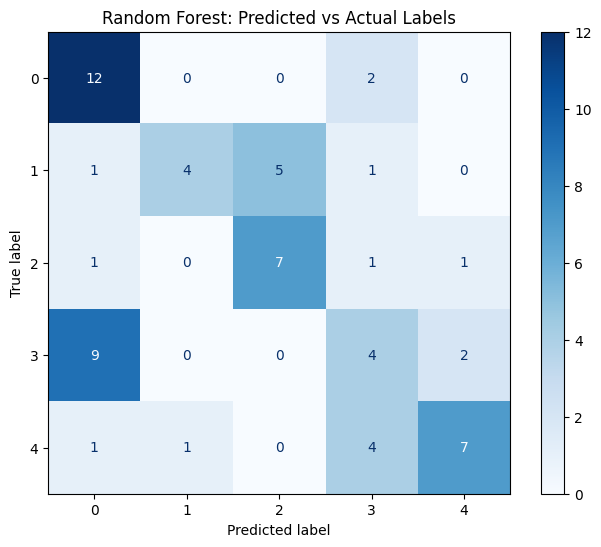

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score 
import time
from matplotlib import pyplot as plt
from random import randint


# make train test split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

print("random forest model")

fx_train = x_train.reshape(len(x_train),-1)
fx_test = x_test.reshape(len(x_test),-1)

rf_model = RandomForestClassifier(n_estimators=100)
rf_model.fit(fx_train, y_train)

y_pred = rf_model.predict(fx_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax)
plt.title("Random Forest: Predicted vs Actual Labels")
plt.show()